# 06 · Épocas e um `alpha` mais pequeno no TF-IDF

Spike E4-S5 do [`docs/backlog.md`](../docs/backlog.md). Os números que saem daqui vão para a secção 15 do [`docs/qualidade_dados.md`](../docs/qualidade_dados.md).

**Porquê:** o TF-IDF vai ser a régua do BERTimbau e do Albertina, e ficaram duas coisas por medir no E4-S4 (notebook 05):

- **o `alpha` = 0,00000001.** O 0,0000001 ganhou no E4-S4, mas era o extremo da lista testada: quando o melhor valor fica no extremo, não se sabe se um mais pequeno seria ainda melhor;
- **as épocas.** Uma *época* é uma passagem completa por todos os exemplos de treino. O `SGDClassifier` treina um classificador "sim/não" por etiqueta (cerca de 3 000), e cada um para sozinho quando a perda (o erro) **no treino** não desce pelo menos 0,001 × o número de exemplos em 5 épocas seguidas: é a *paragem automática*, a regra por defeito do scikit-learn. Nunca se mediu se parar noutra época dá melhores sugestões na **validação**.

**As opções e a ordem das comparações** estão em [`experiencias/e4_s5.yaml`](../experiencias/e4_s5.yaml), escrito antes de correr; este notebook lê esse ficheiro, para não poder decidir com uma lista diferente da que se treinou. Três passos, pela ordem:

1. **`alpha`**, com τ = 0: o 0,00000001 contra o 0,0000001 (em vigor);
2. **τ**, só se o `alpha` mudar (lista e regra do E4-S4);
3. **épocas**, com o `alpha` e o τ em vigor: a regra por defeito (em vigor) contra um número fixo de épocas, igual para todas as etiquetas e sem paragem automática: 3, 6, 12, 18 e 24.

Em cada passo, o candidato só substitui a opção em vigor se ganhar com a regra do E4-T1 (top-5 no código completo decide, com o bootstrap; o top-5 na classe é a guarda); em empate fica a que já estava.

**Também se mostra** (sem entrar na decisão): o F1 macro e uma curva do top-5 em cada época de 1 a 24. A curva é uma **aproximação**: foi treinada uma época de cada vez (`partial_fit`), e assim todas as épocas veem os exemplos pela mesma ordem, enquanto um treino normal os baralha de outra maneira em cada época (`scripts/curva_epocas.py` explica porquê). Os 5 pontos que decidem vêm de treinos normais separados.

**Os treinos** correram num pod da Runpod com 32 processadores (`scripts/correr_experiencia.py`, vários treinos ao mesmo tempo), com o treino completo e N = 10. Os ficheiros estão em `metrics/e4_s5/`. O teste não se abre aqui.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import baselines as bl
import comparison as cmp
import correr_experiencia as ce
import evaluation as ev
import tfidf

RAIZ = Path.cwd().parent
DATA = RAIZ / "data" / "processed"
METRICS = RAIZ / "metrics"
EXP = ce.ler(RAIZ / "experiencias" / "e4_s5.yaml")
SAIDA = RAIZ / EXP["saida"]
N_MIN = EXP["n_min"]
ALPHAS = [EXP["alpha"]["em_vigor"], *EXP["alpha"]["candidatos"]]      # o 1.º é o em vigor
TAUS = [EXP["tau"]["em_vigor"], *EXP["tau"]["candidatos"]]            # o 1.º é o em vigor no passo 2
EPOCAS = EXP["epocas"]["candidatos"]                                   # em vigor: a regra por defeito

treino = pd.read_parquet(DATA / "treino.parquet", columns=["codigo"])
val = pd.read_parquet(DATA / "validacao.parquet", columns=["idcontrato", "codigos", "visto_no_treino"])
print(f"treino: {len(treino):,} exemplos · validação: {len(val):,} contratos · N = {N_MIN}")
print("alpha:", ALPHAS, "· τ:", TAUS, "· épocas:", EPOCAS, "· curva até", EXP["curva_epocas"])

treino: 478,384 exemplos · validação: 23,945 contratos · N = 10
alpha: [1e-07, 1e-08] · τ: [0.0, 0.25, 0.5, 1.0] · épocas: [3, 6, 12, 18, 24] · curva até 24


## Os treinos

Uma linha por treino, lida do `treino.json` de cada um. Na regra por defeito, **épocas** é o máximo entre as etiquetas (o scikit-learn só guarda esse); com épocas fixas é o número pedido. Os tempos são de treinos que correram ao mesmo tempo no mesmo pod (2 de cada vez na fase do `alpha`, com 16 processadores cada; 4 de cada vez na das épocas, com 8), por isso servem para comparar entre si dentro de cada fase, não com os do E4-S4.

In [2]:
pastas = {f"alpha {a:g}": ce.pasta_alpha(EXP, a) for a in ALPHAS} | \
         {f"{k} épocas": ce.pasta_epocas(EXP, k) for k in EPOCAS}
info = {nome: json.loads((RAIZ / p / "treino.json").read_text(encoding="utf-8")) for nome, p in pastas.items()}
if any(i["n_min"] != N_MIN for i in info.values()):
    raise ValueError("os treinos não usaram todos o N do YAML")
if any(i["validacao"]["contratos"] != len(val) for i in info.values()):
    raise ValueError("algum treino sugeriu para outra validação")
pd.DataFrame({nome: {"alpha": f'{i["alpha"]:g}', "épocas pedidas": i["epocas"] or "regra por defeito",
                     "épocas feitas (máx.)": i["n_iter"][0], "tol": i["tol"], "etiquetas": i["etiquetas"],
                     "vocabulário": i["vocabulario"], "treinar (s)": i["tempo_vetorizar_treinar_s"],
                     "sugerir (s)": i["tempo_sugerir_s"], "pico de memória (MiB)": i["pico_rss_mb"]}
              for nome, i in info.items()}).T

,alpha,épocas pedidas,épocas feitas (máx.),tol,etiquetas,vocabulário,treinar (s),sugerir (s),pico de memória (MiB)
alpha 1e-07,1e-07,regra por defeito,12,0.001,3000,402084,224.51,29.49,10040
alpha 1e-08,1e-08,regra por defeito,30,0.001,3000,402084,243.97,29.7,10052
3 épocas,1e-07,3,3,None,3000,402084,208.94,22.91,9984
6 épocas,1e-07,6,6,None,3000,402084,411.36,23.44,9993
12 épocas,1e-07,12,12,None,3000,402084,821.14,23.65,9969
18 épocas,1e-07,18,18,None,3000,402084,1229.21,30.63,9989
24 épocas,1e-07,24,24,None,3000,402084,1580.89,23.29,9952


## As sugestões

Um ficheiro por opção. As verificações são as dos notebooks 04 e 05: uma linha por contrato da validação, alinhada pelo `idcontrato` (nunca pela posição), com 5 códigos distintos de 8 dígitos. Usam `raise` e não `assert`, porque o Python ignora os `assert` quando corre com `-O`.

In [3]:
CODIGO = re.compile(r"\d{8}")


def nome_tau(tau):
    return "sugestoes_validacao.parquet" if tau == 0 else f"sugestoes_validacao_tau{tau:g}.parquet"


def ler(path):
    sug = pd.read_parquet(path, columns=["idcontrato", "sugestoes"])
    sug["idcontrato"] = sug["idcontrato"].astype(str)
    if sug["idcontrato"].duplicated().any() or set(sug["idcontrato"]) != set(val["idcontrato"]):
        raise ValueError(f"{path}: os contratos não são os da validação, um por linha")
    s = sug.set_index("idcontrato")["sugestoes"].reindex(val["idcontrato"]).map(list)
    s.index = val.index
    if not s.map(lambda l: len(set(l)) == ev.TOP_K and all(CODIGO.fullmatch(c) for c in l)).all():
        raise ValueError(f"{path}: há contratos sem {ev.TOP_K} códigos distintos de 8 dígitos")
    return s


por_alpha = {(a, t): ler(RAIZ / ce.pasta_alpha(EXP, a) / nome_tau(t)) for a in ALPHAS for t in TAUS}
print(f"{len(por_alpha)} opções da fase do alpha lidas · ok")

8 opções da fase do alpha lidas · ok


**Repetível?** O treino com `alpha` = 0,0000001 e a regra por defeito é o mesmo do E4-S4 (mesmos dados, mesma semente, mesmo código do modelo). O backlog pede esta confirmação antes de qualquer conclusão: se as sugestões não forem iguais às do E4-S4 (76,9% no código completo e 82,9% na classe, com τ = 0,25), nenhuma comparação com o E4-S4 vale. Mudou só o número de processadores (16 em vez de 8), que não muda o modelo (há um teste a isso em `tests/unit/test_tfidf.py`).

In [4]:
for t in TAUS:
    e4s4 = ler(METRICS / "e4_s4" / "alpha_1e-7" / nome_tau(t))
    iguais = (e4s4 == por_alpha[(ALPHAS[0], t)]).mean()
    print(f"τ {t:g}: sugestões iguais às do E4-S4: {iguais:.2%}")
    if iguais < 1:
        raise ValueError("o treino em vigor não repetiu o E4-S4")

τ 0: sugestões iguais às do E4-S4: 100.00%


τ 0.25: sugestões iguais às do E4-S4: 100.00%


τ 0.5: sugestões iguais às do E4-S4: 100.00%


τ 1: sugestões iguais às do E4-S4: 100.00%


## Passo 1: o `alpha` (com τ = 0)

Cada candidato contra a opção em vigor, com o bootstrap emparelhado (1 000 amostras da validação, a mesma amostra para os dois). `cmp.choose` aplica a regra do E4-T1: devolve `"b"` se o candidato ganhar e `"a"` se ficar a opção em vigor. A coluna "candidato melhor em" é a parte das amostras em que o candidato ficou à frente: a diferença só conta se for pelo menos 95% (ou no máximo 5%, a favor da opção em vigor).

In [5]:
def duelo(em_vigor, candidato):
    """Top-5 no código e na classe, em vigor (a) contra candidato (b), e a decisão."""
    res = {}
    for medida in ("codigo", "classe"):
        a = cmp.weighted_mean(ev.hits(em_vigor, val["codigos"], medida, ev.TOP_K))
        b = cmp.weighted_mean(ev.hits(candidato, val["codigos"], medida, ev.TOP_K))
        res[medida] = cmp.paired_bootstrap(a, b, len(val))
    return res, cmp.choose(res["codigo"], res["classe"], default="a")


def mostrar(nome_a, nome_b, res, escolha):
    for medida, r in res.items():
        print(f"  {medida:7s} {nome_a}: {r['a']:.2%}  {nome_b}: {r['b']:.2%}  "
              f"diferença {r['b'] - r['a']:+.2%}  candidato melhor em {r['b_melhor']:.0%} das amostras")
    print(f"  -> fica {nome_b if escolha == 'b' else nome_a}")


alpha = ALPHAS[0]
for cand in ALPHAS[1:]:
    res, escolha = duelo(por_alpha[(alpha, 0.0)], por_alpha[(cand, 0.0)])
    print(f"alpha {alpha:g} (em vigor) contra alpha {cand:g}:")
    mostrar(f"alpha {alpha:g}", f"alpha {cand:g}", res, escolha)
    if escolha == "b":
        alpha = cand
print(f"\nalpha escolhido: {alpha:g}")

alpha 1e-07 (em vigor) contra alpha 1e-08:
  codigo  alpha 1e-07: 76.91%  alpha 1e-08: 69.44%  diferença -7.47%  candidato melhor em 0% das amostras
  classe  alpha 1e-07: 82.20%  alpha 1e-08: 75.79%  diferença -6.41%  candidato melhor em 0% das amostras
  -> fica alpha 1e-07

alpha escolhido: 1e-07


## Passo 2: o τ (só se o `alpha` mudou)

Se o `alpha` não mudou, o τ fica o do E4-S4 (`tfidf.TAU`), que foi escolhido com este mesmo `alpha`, e não se volta a escolher.

In [6]:
if alpha == ALPHAS[0]:
    tau = tfidf.TAU
    print(f"o alpha não mudou: o τ fica o do E4-S4, {tau:g}")
else:
    tau = TAUS[0]
    for cand in TAUS[1:]:
        res, escolha = duelo(por_alpha[(alpha, tau)], por_alpha[(alpha, cand)])
        print(f"τ {tau:g} (em vigor) contra τ {cand:g}:")
        mostrar(f"τ {tau:g}", f"τ {cand:g}", res, escolha)
        if escolha == "b":
            tau = cand
print(f"\nem vigor para o passo 3: alpha {alpha:g}, τ {tau:g}")

o alpha não mudou: o τ fica o do E4-S4, 0.25

em vigor para o passo 3: alpha 1e-07, τ 0.25


## Passo 3: as épocas (com o `alpha` e o τ em vigor)

A opção em vigor é a regra por defeito (o treino da fase do `alpha` com o `alpha` escolhido). Cada número fixo de épocas compara-se com ela pela ordem do YAML; se ganhar, passa a ser a opção em vigor para os seguintes.

Os treinos com épocas fixas foram lançados com o `alpha` e o τ que o passo 1 e o passo 2 deram; se o notebook chegar aqui com outros, os ficheiros não servem e o notebook para.

In [7]:
for k in EPOCAS:
    i = info[f"{k} épocas"]
    if i["alpha"] != alpha or tau not in i["taus"]:
        raise ValueError(f"{k} épocas: treinado com alpha {i['alpha']:g} e τ {i['taus']}, não com {alpha:g} e {tau:g}")

opcoes = {"regra por defeito": por_alpha[(alpha, tau)]} | \
         {f"{k} épocas": ler(RAIZ / ce.pasta_epocas(EXP, k) / nome_tau(tau)) for k in EPOCAS}
epocas = "regra por defeito"
for k in EPOCAS:
    cand = f"{k} épocas"
    res, escolha = duelo(opcoes[epocas], opcoes[cand])
    print(f"{epocas} (em vigor) contra {cand}:")
    mostrar(epocas, cand, res, escolha)
    if escolha == "b":
        epocas = cand
print(f"\nescolhido: alpha {alpha:g}, τ {tau:g}, {epocas}")

regra por defeito (em vigor) contra 3 épocas:
  codigo  regra por defeito: 76.94%  3 épocas: 74.46%  diferença -2.48%  candidato melhor em 0% das amostras
  classe  regra por defeito: 82.94%  3 épocas: 81.82%  diferença -1.12%  candidato melhor em 0% das amostras
  -> fica regra por defeito


regra por defeito (em vigor) contra 6 épocas:
  codigo  regra por defeito: 76.94%  6 épocas: 76.84%  diferença -0.11%  candidato melhor em 18% das amostras
  classe  regra por defeito: 82.94%  6 épocas: 82.73%  diferença -0.21%  candidato melhor em 5% das amostras
  -> fica regra por defeito


regra por defeito (em vigor) contra 12 épocas:
  codigo  regra por defeito: 76.94%  12 épocas: 77.52%  diferença +0.58%  candidato melhor em 100% das amostras
  classe  regra por defeito: 82.94%  12 épocas: 83.13%  diferença +0.19%  candidato melhor em 94% das amostras
  -> fica 12 épocas


12 épocas (em vigor) contra 18 épocas:
  codigo  12 épocas: 77.52%  18 épocas: 77.48%  diferença -0.05%  candidato melhor em 29% das amostras
  classe  12 épocas: 83.13%  18 épocas: 83.15%  diferença +0.02%  candidato melhor em 59% das amostras
  -> fica 12 épocas


12 épocas (em vigor) contra 24 épocas:
  codigo  12 épocas: 77.52%  24 épocas: 78.35%  diferença +0.82%  candidato melhor em 100% das amostras
  classe  12 épocas: 83.13%  24 épocas: 84.11%  diferença +0.98%  candidato melhor em 100% das amostras
  -> fica 24 épocas

escolhido: alpha 1e-07, τ 0.25, 24 épocas


## Todas as opções lado a lado

A régua é a do E4-T2, com o mesmo N. Além das métricas da regra (top-5 no código completo e na classe), mostram-se duas que não entram na decisão:
- **F1 macro** no código completo: a média do F1 de cada etiqueta. Sobe quando o modelo acerta também etiquetas pouco frequentes.
- **1.ª sugestão na régua:** a parte dos contratos em que a 1.ª sugestão é uma das 5 etiquetas da régua.

In [8]:
top = bl.most_common_labels(treino["codigo"], n_min=N_MIN)
regua = bl.suggest_most_common(top, val.index)
novo = ~val["visto_no_treino"]


def linha(s):
    rep = ev.report(s, val["codigos"], val["visto_no_treino"])
    return {
        "top-5 código": rep.loc[("todos", "codigo"), "top5"],
        "top-5 classe": rep.loc[("todos", "classe"), "top5"],
        "top-5 código (novo)": rep.loc[("texto novo", "codigo"), "top5"],
        "top-5 classe (novo)": rep.loc[("texto novo", "classe"), "top5"],
        "top-1 código": rep.loc[("todos", "codigo"), "top1"],
        "F1 macro código": rep.loc[("todos", "codigo"), "f1_macro"],
        "1.ª sugestão na régua": s.map(lambda l: l[0] in top).mean(),
    }


tabela = pd.DataFrame({**{(f"alpha {a:g}", f"τ {t:g}", "regra por defeito"): linha(s) for (a, t), s in por_alpha.items()},
                       **{(f"alpha {alpha:g}", f"τ {tau:g}", nome): linha(s) for nome, s in opcoes.items() if nome != "regra por defeito"},
                       ("régua", "-", "-"): linha(regua)}).T
tabela.style.format({c: "{:.1%}" for c in tabela.columns if c != "F1 macro código"} | {"F1 macro código": "{:.4f}"})

## A curva: top-5 em cada época de 1 a 24 (só para ver)

Calculada com as sugestões que `scripts/curva_epocas.py` gravou depois de cada época, com o mesmo `alpha` e τ. Os pontos são os treinos normais com épocas fixas (os que decidem) e a linha tracejada é a regra por defeito. Onde a curva e os pontos se afastam, é o efeito da ordem dos exemplos (a curva vê-os sempre pela mesma ordem). Com 24 comparações, alguma época ganharia só por sorte, por isso a curva não entra na decisão.

In [9]:
curva_info = json.loads((RAIZ / ce.pasta_curva(EXP) / "curva.json").read_text(encoding="utf-8"))
if curva_info["alpha"] != alpha or curva_info["tau"] != tau:
    raise ValueError("a curva foi treinada com outro alpha ou τ")
curva = {}
for e in range(1, curva_info["epocas"] + 1):
    s = ler(RAIZ / ce.pasta_curva(EXP) / f"sugestoes_epoca_{e:02d}.parquet")
    rep = ev.report(s, val["codigos"], val["visto_no_treino"])
    curva[e] = {m: rep.loc[("todos", m), "top5"] for m in ("codigo", "classe")}
curva = pd.DataFrame(curva).T
curva.index.name = "época"
curva.style.format("{:.2%}")

,codigo,classe
época,,
1,65.12%,74.43%
2,71.67%,79.58%
3,74.33%,80.94%
4,75.67%,81.92%
5,76.39%,82.37%
6,76.85%,82.58%
7,77.09%,82.80%
8,77.20%,82.86%
9,77.37%,82.96%


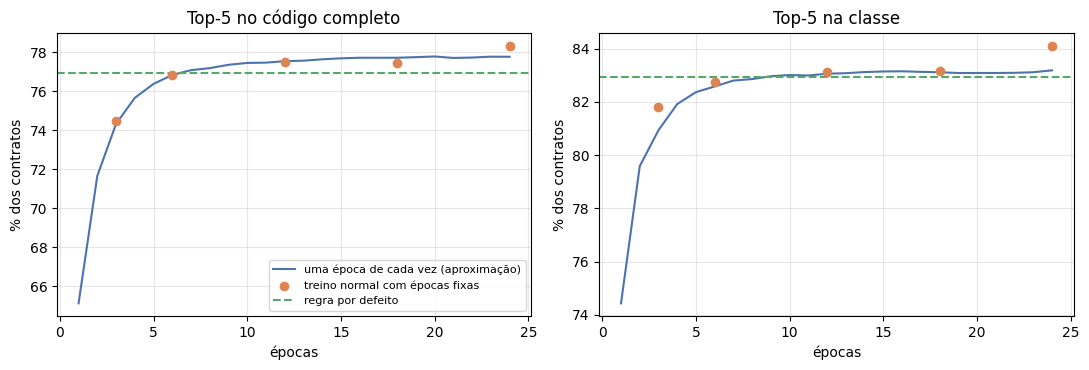

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, (medida, titulo) in zip(axes, (("top-5 código", "Top-5 no código completo"), ("top-5 classe", "Top-5 na classe"))):
    col = "codigo" if medida == "top-5 código" else "classe"
    ax.plot(curva.index, curva[col] * 100, color="#4C72B0", label="uma época de cada vez (aproximação)")
    pts = tabela.xs((f"alpha {alpha:g}", f"τ {tau:g}"), level=(0, 1))
    ks = [k for k in EPOCAS]
    ax.scatter(ks, [pts.loc[f"{k} épocas", medida] * 100 for k in ks], color="#DD8452", zorder=3,
               label="treino normal com épocas fixas")
    ax.axhline(pts.loc["regra por defeito", medida] * 100, color="#55A868", ls="--", label="regra por defeito")
    ax.set_title(titulo)
    ax.set_xlabel("épocas")
    ax.set_ylabel("% dos contratos")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()

## O escolhido contra o E4-S4 e contra a régua

A avaliação completa (as quatro medidas, todos os contratos e texto novo) do escolhido, ao lado do modelo do E4-S4. E o critério do E4-H1 repetido para o escolhido: continua a bater a régua no top-5 do código completo e da classe, em todos os contratos e no texto novo?

In [11]:
escolhido = opcoes[epocas]
e4s4 = ler(METRICS / "e4_s4" / "alpha_1e-7" / nome_tau(tfidf.TAU))
lado = pd.concat({"escolhido": ev.report(escolhido, val["codigos"], val["visto_no_treino"]),
                  "E4-S4": ev.report(e4s4, val["codigos"], val["visto_no_treino"])}, axis=1)
lado.style.format("{:.1%}", subset=[c for c in lado.columns if c[1] in ("top1", "top5")]) \
    .format("{:.4f}", subset=[c for c in lado.columns if c[1] == "f1_macro"]) \
    .format("{:,.0f}", subset=[c for c in lado.columns if c[1] == "contratos"])

In [12]:
linhas = {}
for grupo, mask in (("todos", slice(None)), ("texto novo", novo)):
    comp = cmp.compare(escolhido[mask], regua[mask], val["codigos"][mask])
    for medida in ("codigo", "classe"):
        r = comp.loc[(medida, "top5")]
        linhas[(grupo, medida)] = {"escolhido": r["a"], "régua": r["b"], "conta": r["conta"],
                                   "bate a régua": bool(r["conta"] and r["a"] > r["b"])}
verdict = pd.DataFrame(linhas).T
print(verdict)
print("\nContinua a bater a régua:", "SIM" if verdict["bate a régua"].all() else "NÃO")

                  escolhido     régua conta bate a régua
todos      codigo  0.783482  0.263237  True         True
           classe  0.841105  0.155976  True         True
texto novo codigo  0.751404  0.237187  True         True
           classe  0.821808  0.148424  True         True

Continua a bater a régua: SIM
